# Session 12: Linear regression with basis functions

Linear regression is more powerful than it first looks. By transforming the basis the data is represented in, a linear model
can fit data in a high-dimensional space and reach good accuracy with a very simple model.

The pre-class work: classify functions by linearity, describe radial and polynomial basis functions, explain ridge and lasso,
then model the Yosemite temperatures with radial basis functions.

## Part 1: Basic questions

Guess first, then check with an LLM. The guesses were written before asking, and the LLM gave definitions of the terms only.

```
BOX 1: MY INITIAL GUESSES (written before I asked an LLM for answers)

Linearity: first is linear in both, second is linear in params, third is linear in variables, fourth is neither,

Basis functions: radial function is reducing the radius length

polynomial has 5 weights and 4 observations so each w is scaling the data point

Regularization: ridge and lasso add a penalty to the OLS to constrain model coefficients

BOX 2: CHECKING WITH AN LLM

(Before guessing, the LLM gave me definitions of the terms, which the assignment allows. It did not answer the questions. I then pasted my guesses.)

LLM:

Your Q1 classifications are all correct. Q2 is where you lose the most, and Q3 is right but too thin.

Q1: all four right. The assignment also asks how you know, so use these reasons:

1. Both. It is a straight line in x, and the β's appear only to the first power. One trap: β1x + β2x is just (β1 + β2)x, so β1 and β2 can't be told apart.

2. Parameters only. The β's are first-power, but x² makes it a curve in x.

3. Variables only. It is a straight line in x, but β2² is not linear in β2.

4. Neither. It has both the x² and the β2².

Q2: needs work.

Radial basis function f(x) = w0 + w1|x − c|:

- Shape: a V with its tip at x = c. It flips upside down if w1 is negative.

- Parameters: c is the center, w0 is the height of the tip, and w1 is how steeply the arms rise.

- Transformation: it replaces x with its distance from c, so points the same distance on either side get the same value, which folds the line at c. "Reducing the radius length" isn't right, because nothing shrinks. If you meant "turns x into a distance from c", that part is right.

Polynomial f(x) = w0 + w1x + w2x² + w3x³ + w4x⁴:

- Weights: five is correct. Each w scales one power of x, not the data point itself.

- Shape and transformation: a smooth curve that can bend up to three times. It turns x into the five features 1, x, x², x³, x⁴, and it is still linear in the weights, so ordinary least squares works.

- "4 observations": the question never mentions observations, and the 4 is the degree. If you did have 4 data points, though, 5 weights would give infinitely many perfect fits, which is exactly the problem regularization addresses.

Q3: correct, but add the details.

OLS:   minimize Σ (y − wᵀx)²

Ridge: minimize Σ (y − wᵀx)² + λ Σ wⱼ²

Lasso: minimize Σ (y − wᵀx)² + λ Σ |wⱼ|

- λ sets the strength of the penalty, and λ = 0 gives back ordinary regression.

- Ridge shrinks all weights toward zero but rarely makes any exactly zero. Lasso can set some exactly to zero, so it also selects features.

- The purpose is to reduce overfitting by accepting a little bias for less variance.

ME:

no debate, i just didnt understand the radial function

LLM:

The function f(x) = w0 + w1|x − c| works in two steps:

1. Measure the distance. |x − c| is how far x is from a chosen center point c. It doesn't matter which side of c you're on.

2. Fit a line to that distance. The output is w0 + w1 times the distance.

Take c = 3, w0 = 1, w1 = 2:

x = 1: distance 2, f(x) = 5

x = 2: distance 1, f(x) = 3

x = 3: distance 0, f(x) = 1

x = 4: distance 1, f(x) = 3

x = 5: distance 2, f(x) = 5

The values at x = 2 and x = 4 are both 3 because both are one step from c. That gives a V shape with its tip at c.

Parameters: c is where the tip of the V sits. w0 is the height of the tip, the value at x = c. w1 is how steeply the arms rise; if it's negative, the V flips into a peak.

The "transformation" is that the model no longer looks at x itself. It looks at the new feature "distance from c". Rather than "reducing the radius", it measures the distance, and the radius is that distance.

This helps when an outcome depends on closeness to a spot. For example, if x is a position along a road and c is the city center, house prices might peak at c and fall off equally on both sides.

REFLECTION

I did not argue with the LLM's answers, because on checking them I agreed with them. My Q1 classifications were all correct. My radial function answer was wrong: I described it as "reducing the radius length", but it turns x into its distance from the center c and fits a line to that distance. I also mixed up the degree of the polynomial (4) with a number of observations, which the question never gave. My ridge and lasso answer was right but missing the difference between them: ridge adds a squared penalty and shrinks weights, while lasso adds an absolute-value penalty and can set weights exactly to zero. It was also missing λ, the penalty strength.
```

## Part 2: Core questions, Yosemite temperatures

Temperature every 5 minutes at Yosemite Village, 2011 to 2016. Describe the variables, explain why a straight line does badly,
fit a linear parameter model with radial basis functions, and record a metric.

### The variables

From NOAA's climate-network (USCRN) sub-hourly format; check against the documentation file. Each row is one 5-minute reading.

- **Time and place:** station ID (`WBANNO`), date and time in UTC (`UTC_DATE` as YYYYMMDD, `UTC_TIME` as HHmm), the same in
  local standard time (`LST_DATE`, `LST_TIME`), datalogger version (`CRX_VN`), `LONGITUDE`, `LATITUDE`.
- **Temperature and moisture:** `AIR_TEMPERATURE` (C, 5-minute average), `PRECIPITATION` (mm), `RELATIVE_HUMIDITY` (%),
  `SOIL_MOISTURE_5`, `SOIL_TEMPERATURE_5` (C at 5 cm), `WETNESS`.
- **Sun, surface and wind:** `SOLAR_RADIATION` (W/m^2), `SURFACE_TEMPERATURE` (C, infrared), `WIND_1_5` (m/s at 1.5 m).
- **Quality flags:** one per sensor. Missing values are coded -9999, which is why the code filters with `> -1000`.

The code uses only `UTC_DATE`, `UTC_TIME` and `AIR_TEMPERATURE`. The time is UTC, so the daily cycle is shifted by 7 to 8 hours.

### Why the straight line does so badly

The line regresses temperature on time of day only. Real temperature has two repeating cycles that a line can't follow: a daily
cycle (cold at night, warm in the afternoon) and a yearly cycle (the seasons). Because the model ignores the date, the winter
and summer readings at each time of day pile up as a tall vertical smear that no single line can cut through. Both cycles are
periodic, so the shapes needed are smooth bumps that wrap around.

### Code cell 1: the straight-line fit (reads the data straight from NOAA)

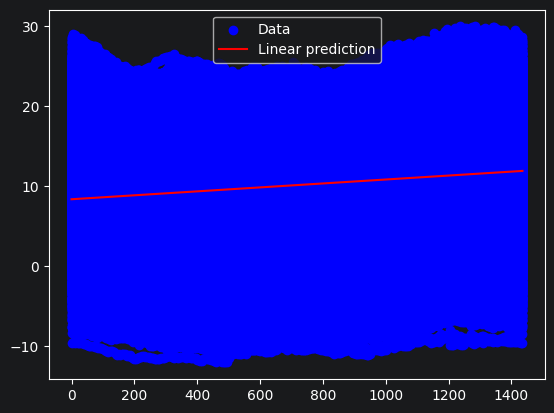

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

years = range(2011, 2017)
base = "https://www.ncei.noaa.gov/pub/data/uscrn/products/subhourly01/%d/CRNS0101-05-%d-CA_Yosemite_Village_12_W.txt"
files = [base % (y, y) for y in years]
usecols = [1, 2, 8]

data = [np.loadtxt(f, usecols=usecols) for f in files]
data = np.vstack(data)

# Map from HHmm to an integer
data[:, 1] = np.floor_divide(data[:, 1], 100) * 60 + np.mod(data[:, 1], 100)
valid = data[:, 2] > -1000

x_train = data[valid, 1].reshape(-1, 1)
y_train = data[valid, 2]
regr = linear_model.LinearRegression()
regr.fit(x_train, y_train)

x_predict = [[0], [1435]]
y_predict = regr.predict(x_predict)

plt.scatter(data[valid, 1], data[valid, 2], label='Data', color='b')
plt.plot(x_predict, y_predict, label='Linear prediction', color='r')
plt.legend(loc='best')
plt.show()

### Code cell 2: a linear parameter model with radial basis functions (weight from height)

Four people, six bump centers. Each height becomes six numbers (its closeness to each center), and ridge regression fits the
weights on those six numbers.

centers.shape (6, 1)
heights.shape (4, 1)
weights.shape (4, 1)
x.shape (4, 6)
Original inputs [[1.32]
 [1.45]
 [1.66]
 [1.88]]
RBF repr [[0.87237724 0.98098315 0.99150297 0.90074477 0.73550349 0.53981255]
 [0.76337949 0.92004441 0.99667222 0.97044553 0.84930804 0.66808937]
 [0.55945063 0.75417312 0.91380934 0.9952115  0.97420519 0.85715773]
 [0.35610369 0.53981255 0.73550349 0.90074477 0.99150297 0.98098315]]
Score on training data =  0.9079130664442814
all_x.shape (1000, 1)
expanded_x.shape (1000, 6)
all_y.shape (1000, 1)


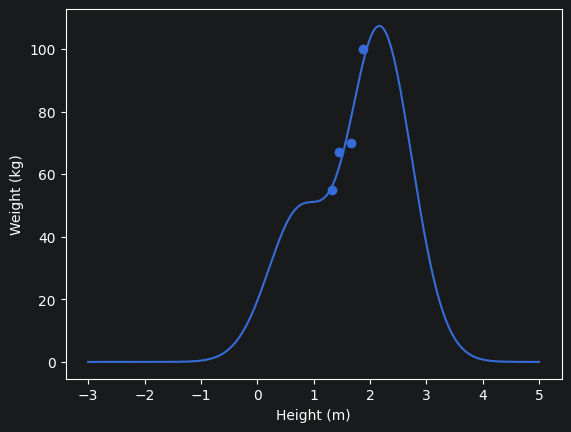

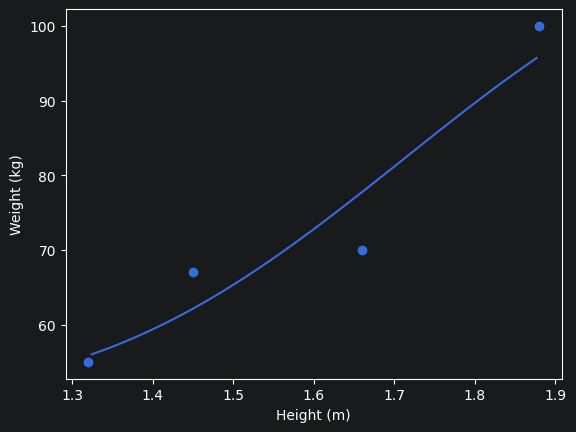

In [3]:
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt
import numpy as np

# Try to predict weight as a function of height.
# Physics would suggest that weight is proportional to volume,
# and volume is proportional to height^3.  However we will
# use a linear parameter model with radial basis functions
# to model this nonlinear relationship.

heights = np.asarray([1.32, 1.45, 1.66, 1.88]).reshape(-1, 1)
weights = np.asarray([55, 67, 70, 100]).reshape(-1, 1)
centers = np.asarray([1.0, 1.2, 1.4, 1.6, 1.8, 2.0]).reshape(-1, 1)
print("centers.shape", centers.shape)
print("heights.shape", heights.shape)
print("weights.shape", weights.shape)

# I recommend playing around with these parameters and seeing how well you fit
# the data.  Changing one of the parameters will change the optimal value of
# the other:
sigma = 0.75
alpha = 0.001

# New representation:
x = rbf_kernel(heights, centers, gamma=1.0 / sigma)
print("x.shape", x.shape)
print("Original inputs", heights)
print("RBF repr", x)

# Now go and fit a linear model between x and height
regr = Ridge(alpha=alpha, fit_intercept=False)
regr.fit(x, weights)
print("Score on training data = ", regr.score(x, weights))
all_x = np.linspace(-3.0, 5.0, 1000).reshape(-1, 1)

# New representation:
expanded_x = rbf_kernel(all_x, centers, gamma=1.0 / sigma)
all_y = regr.predict(expanded_x)
all_y = all_y.reshape(-1, 1)
print("all_x.shape", all_x.shape)
print("expanded_x.shape", expanded_x.shape)
print("all_y.shape", all_y.shape)

# Show that the predictions tend to zero far away from inputs
plt.figure()
plt.plot(all_x, all_y)
plt.scatter(heights, weights)
plt.xlabel("Height (m)")
plt.ylabel("Weight (kg)")


# Zoom in and see how well predictions fit the data
zoom_ind = (all_x > heights.min()) & (all_x < heights.max())
plt.figure()
plt.plot(all_x[zoom_ind], all_y[zoom_ind])
plt.scatter(heights, weights)
plt.xlabel("Height (m)")
plt.ylabel("Weight (kg)")
plt.show()

### Code cell 3: metrics

R^2, RMSE and MAE are measured on the same 4 people the model was fitted on. Leave-one-out fits on 3 people and predicts the
4th, repeated for each person, so it is the honest number. Always guessing the average weight of the other three people gives
22.1 kg, so the model barely beats a plain guess on new people even though R^2 looks great.

In [4]:
#metrics here
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import LeaveOneOut

pred = regr.predict(x)
print("R^2  ", regr.score(x, weights))
print("RMSE ", mean_squared_error(weights, pred) ** 0.5, "kg")
print("MAE  ", mean_absolute_error(weights, pred), "kg")

# leave-one-out: fit on 3 people, predict the 4th, repeat for each person
loo_pred = np.zeros(weights.shape)
for train_idx, test_idx in LeaveOneOut().split(heights):
    m = Ridge(alpha=alpha, fit_intercept=False).fit(x[train_idx], weights[train_idx])
    loo_pred[test_idx] = m.predict(x[test_idx])
print("leave-one-out RMSE", mean_squared_error(weights, loo_pred) ** 0.5, "kg")

R^2   0.9079130664442814
RMSE  5.027709544220386 kg
MAE   4.389573168137563 kg
leave-one-out RMSE 19.140418508318547 kg


## Part 3: Extension, search the hyperparameters on the temperature data

The best R^2 available for a linear regression model using an RBF on this data set is around 0.82. Search the hyperparameters
(the number, heights, weights and centers of the RBFs), try to hit the benchmark, and answer:

1. What performance were you able to achieve?
2. Explain what applying lasso to your model might do.

**Answers**

A calendar-only RBF model (daily x yearly bumps) reached R² 0.62 on all the data and 0.59 on unseen years (2015-2016). Adding RBFs along the whole 2011-2016 timeline raised R² on all the data to 0.80 with one bump per week and 0.92 with one bump every 3 days, above the 0.82 benchmark. But on held-out weeks these models scored only 0.34 and 0.48, below the calendar-only model's 0.63, so the extra gain is the model fitting the weather in the weeks it was trained on. A stronger ridge penalty (alpha = 1000) with weekly bumps gave R² 0.66 on all data and 0.64 on held-out weeks, the best held-out score I found.



Lasso adds a penalty λ·Σ|w| to the squared error, which pushes weights down and sets some exactly to zero. For this model that means:

Pruning. Bumps that don’t help get switched off, so you could start with many bumps and let lasso decide which centers matter, instead of choosing the number by hand.

A sparser, simpler model. Training R² drops slightly. Held-out R² stays about the same, or improves if the model was overfitting.

best 5 settings (ranked by R^2 on the unseen years 2015-2016)
  daily bumps 12, yearly bumps  8, width 0.9, interaction True  -> R^2 train 0.623, unseen years 0.590
  daily bumps  8, yearly bumps  8, width 0.9, interaction True  -> R^2 train 0.623, unseen years 0.590
  daily bumps  6, yearly bumps  8, width 0.9, interaction True  -> R^2 train 0.623, unseen years 0.590
  daily bumps 12, yearly bumps 12, width 1.2, interaction True  -> R^2 train 0.629, unseen years 0.589
  daily bumps  8, yearly bumps 12, width 1.2, interaction True  -> R^2 train 0.628, unseen years 0.589


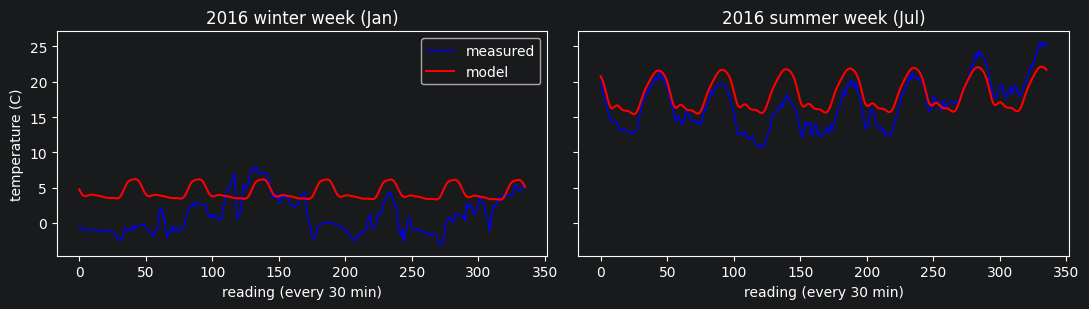

bumps along the timeline  |  R^2 on all data (compare with 0.82)  |  R^2 on held-out weeks
none (calendar only)              |  0.619                                |  0.625
one every 30 days (113 bumps)     |  0.682                                |  0.542
one every 14 days (196 bumps)     |  0.723                                |  0.267
one every 7 days (353 bumps)      |  0.802                                |  0.342
one every 3 days (770 bumps)      |  0.915                                |  0.483
ridge alpha      1: R^2 all data 0.802, held-out weeks 0.342
ridge alpha    100: R^2 all data 0.733, held-out weeks 0.617
ridge alpha   1000: R^2 all data 0.661, held-out weeks 0.639
ridge alpha  10000: R^2 all data 0.508, held-out weeks 0.501


In [5]:
#hyperparameter search
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

# data[:, 0] = UTC date (YYYYMMDD), data[:, 1] = minute of day (from the first cell), data[:, 2] = temperature
d = data[valid]
dates = pd.to_datetime(d[:, 0].astype(int).astype(str), format="%Y%m%d")
year = dates.year.values
minute = d[:, 1]
y = d[:, 2]

# Temperature repeats every day and every year, so describe each reading by where it falls on two circles.
theta_day = 2 * np.pi * minute / 1440
theta_year = 2 * np.pi * (dates.dayofyear.values - 1 + minute / 1440) / 365.25


def circ_rbf(theta, K, width):
    """K Gaussian bumps spaced evenly around a circle (so 23:55 sits next to 00:00).
    `width` is the bump width as a fraction of the gap between neighbouring centres."""
    centers = 2 * np.pi * np.arange(K) / K
    sigma = width * 2 * np.pi / K
    gap = np.angle(np.exp(1j * (theta[:, None] - centers[None, :])))  # signed distance around the circle
    return np.exp(-0.5 * (gap / sigma) ** 2)


def features(idx, Kd, Ky, width, interact):
    """Daily bumps, yearly bumps, and (optionally) every daily bump times every yearly bump,
    which lets the shape of the day change with the season."""
    D = circ_rbf(theta_day[idx], Kd, width)
    Y = circ_rbf(theta_year[idx], Ky, width)
    cols = [D, Y]
    if interact:
        cols.append((D[:, :, None] * Y[:, None, :]).reshape(len(D), -1))
    return np.hstack(cols)


STEP = 6  # use every 6th reading (every 30 min) so the search is fast; STEP = 1 uses all the data
sub = np.arange(len(y))[::STEP]
train = sub[year[sub] <= 2014]   # fit on 2011-2014
test = sub[year[sub] >= 2015]    # score on years the model never saw

# ---- search the hyperparameters: number of bumps per cycle, bump width, with/without interaction
# (the weights, i.e. the bump heights, are found by least squares inside each fit)
results = []
for Kd, Ky, width, interact in itertools.product([4, 6, 8, 12], [4, 6, 8, 12], [0.6, 0.9, 1.2], [False, True]):
    Xtr = features(train, Kd, Ky, width, interact)
    model = Ridge(alpha=1e-3).fit(Xtr, y[train])   # tiny ridge penalty only to keep overlapping bumps numerically stable
    r2_train = model.score(Xtr, y[train])
    r2_test = model.score(features(test, Kd, Ky, width, interact), y[test])
    results.append((r2_test, r2_train, Kd, Ky, width, interact))
results.sort(reverse=True)

print("best 5 settings (ranked by R^2 on the unseen years 2015-2016)")
for r2_test, r2_train, Kd, Ky, width, interact in results[:5]:
    print(f"  daily bumps {Kd:2d}, yearly bumps {Ky:2d}, width {width}, interaction {interact!s:5}"
          f" -> R^2 train {r2_train:.3f}, unseen years {r2_test:.3f}")

# ---- best model: refit, then look at a winter week and a summer week in 2016
_, _, Kd, Ky, width, interact = results[0]
best = Ridge(alpha=1e-3).fit(features(train, Kd, Ky, width, interact), y[train])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (label, day0) in zip(axes, (("winter week (Jan)", 10), ("summer week (Jul)", 190))):
    idx = sub[(year[sub] == 2016) & (dates.dayofyear.values[sub] >= day0) & (dates.dayofyear.values[sub] < day0 + 7)]
    ax.plot(y[idx], label="measured", color="b", lw=1)
    ax.plot(best.predict(features(idx, Kd, Ky, width, interact)), label="model", color="r", lw=1.5)
    ax.set_title("2016 " + label)
    ax.set_xlabel("reading (every 30 min)")
axes[0].set_ylabel("temperature (C)")
axes[0].legend()
plt.tight_layout()
plt.show()


# ---- Second cell: add bumps along the whole 2011-2016 timeline to capture weather episodes that last days.
# Run AFTER the previous cell (it reuses `features`, `y`, `dates`, `minute`, `results`).
t_days = (dates - pd.Timestamp("2011-01-01")).days.values + minute / 1440   # days since 2011-01-01 (absolute time)


def line_rbf(t, spacing):
    """Gaussian bumps along a straight line, one every `spacing` days. Not circular: 2013 is not 2014."""
    centers = np.arange(-spacing, t_days.max() + 2 * spacing, spacing)
    return np.exp(-0.5 * ((t[:, None] - centers[None, :]) / spacing) ** 2)


def features2(idx, Kd, Ky, width, spacing):
    """Calendar part (daily x yearly bumps) plus the along-the-timeline bumps."""
    return np.hstack([features(idx, Kd, Ky, width, True), line_rbf(t_days[idx], spacing)])


_, _, Kd, Ky, width, _ = results[0]            # reuse the best calendar settings from the search
idx_all = np.arange(len(y))[::24]              # every 12th reading (hourly) to keep memory modest
block = (t_days[idx_all] // 7).astype(int)     # which week each reading belongs to
rng = np.random.default_rng(0)
held_weeks = rng.choice(np.unique(block), size=len(np.unique(block)) // 5, replace=False)
is_test = np.isin(block, held_weeks)           # hold out a random 20% of whole weeks

print("bumps along the timeline  |  R^2 on all data (compare with 0.82)  |  R^2 on held-out weeks")
for spacing in [None, 30, 14, 7, 3]:           # try 2 or 1 as well if you have the memory
    X = features(idx_all, Kd, Ky, width, True) if spacing is None else features2(idx_all, Kd, Ky, width, spacing)
    full = Ridge(alpha=1.0).fit(X, y[idx_all])
    part = Ridge(alpha=1.0).fit(X[~is_test], y[idx_all][~is_test])
    label = "none (calendar only)" if spacing is None else f"one every {spacing} days ({X.shape[1] - 80} bumps)"
    print(f"{label:34s}|  {full.score(X, y[idx_all]):.3f}                                |  {part.score(X[is_test], y[idx_all][is_test]):.3f}")
    
    # Does stronger regularisation stop the held-out drop? (one bump per week)
X = features2(idx_all, Kd, Ky, width, 7)
for a in [1, 100, 1000, 10000]:
    full = Ridge(alpha=a).fit(X, y[idx_all])
    part = Ridge(alpha=a).fit(X[~is_test], y[idx_all][~is_test])
    print(f"ridge alpha {a:6}: R^2 all data {full.score(X, y[idx_all]):.3f}, held-out weeks {part.score(X[is_test], y[idx_all][is_test]):.3f}")

**Note on the printed bump counts.** The label in the second table subtracts a hard-coded 80 calendar columns, but the best
calendar model has 12 + 8 + 12*8 = 116, so the counts are 36 too high. The true timeline bump counts are 77, 160, 317 and 734.
The R^2 values are not affected. The comment on the `idx_all` line is also out of date: the code uses every 24th reading
(every 2 hours), not every 12th.

## Notes: how the Yosemite features are built

- **Two circles.** Time of day and time of year both repeat, so each reading becomes two angles: where it sits on the daily
  clock and on the yearly clock. This makes 23:55 sit next to 00:00 and December 31 next to January 1.
- **Bumps.** Gaussian bumps are spaced evenly around each circle. A reading lights up the bumps near its position.
- **A weighted sum.** The prediction is `intercept + w1*bump1 + w2*bump2 + ...`. The bumps are fixed; fitting only chooses the
  weights, so the model is linear in its parameters.
- **Interaction.** Every daily bump times every yearly bump lets the shape of the day change with the season.
- **Timeline bumps.** Bumps along the real 2011-2016 timeline can learn "that week was colder than normal", but only for weeks
  the model was fitted on, which is why they score high on all the data and poorly on held-out weeks.

What was searched and what was learned: the number of bumps, their width, the interaction and the timeline spacing were
searched; the centers were fixed (evenly spaced); the heights (weights) were learned by least squares with a ridge penalty.
The search ranked settings by R^2 on the unseen years 2015-2016, so that score is slightly optimistic.